DBSCAN Project

In [33]:
import pandas as pd 
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt


In [34]:
cust_df = pd.read_csv("1632560262896716.csv")
cust_df.shape


(200, 5)

In [35]:
cust_df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [36]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
cust_df['Gender'] = le.fit_transform(cust_df['Gender'])  # Male=1, Female=0

In [37]:
featureset = cust_df[['Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

In [38]:
X = StandardScaler().fit_transform(featureset)

In [39]:
epsilon =0.7
minimumSamples = 7
db =DBSCAN(eps=epsilon , min_samples=minimumSamples).fit(X)
labels = db.labels_
labels

array([-1, -1, -1,  0, -1,  0, -1,  0, -1,  0, -1, -1, -1,  0, -1, -1, -1,
       -1, -1, -1, -1, -1,  1, -1, -1, -1,  1, -1,  1,  0, -1,  0, -1, -1,
        1,  0,  1,  0,  1,  0,  0, -1,  2,  0,  0,  0,  0,  0,  0,  0,  0,
       -1,  0,  2,  0,  2,  0,  2,  0,  2,  2,  3,  0,  0,  2,  3,  0,  0,
        3,  0,  2,  0,  0,  0,  2,  3,  0,  2,  0,  0,  2, -1,  2,  0,  0,
        2,  0,  0,  0,  0,  0,  3,  2,  0,  0,  3,  0,  0,  2,  3,  0,  0,
        2,  3,  2,  0,  0,  2,  2,  2,  2,  0,  0,  3,  0,  0,  0,  0,  0,
        0,  3,  0,  0,  4,  0,  5,  2,  4, -1,  4, -1,  4,  0,  5, -1,  5,
       -1, -1, -1,  5, -1,  4,  0,  5, -1,  4,  2,  5, -1,  4, -1,  4, -1,
        5, -1,  5, -1,  5, -1,  5,  0,  5, -1,  5, -1,  5, -1,  5, -1, -1,
       -1, -1, -1,  4, -1,  5, -1, -1, -1,  4, -1,  5, -1,  5, -1,  4, -1,
       -1, -1,  5, -1,  5, -1, -1, -1, -1, -1, -1, -1, -1])

In [40]:
core_samples_mask = np.zeros_like( labels , dtype=bool)
core_samples_mask[db.core_sample_indices_] = True
core_samples_mask

array([False, False, False,  True, False,  True, False, False, False,
       False, False, False, False,  True, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False,  True, False,  True, False, False, False,  True,
        True, False, False, False, False, False, False,  True, False,
        True,  True,  True, False, False,  True, False,  True, False,
        True, False,  True, False,  True,  True, False, False, False,
        True,  True, False,  True,  True, False,  True,  True,  True,
        True,  True,  True,  True,  True, False,  True,  True,  True,
       False,  True,  True,  True,  True,  True,  True, False,  True,
       False, False,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True, False, False,  True,  True,  True,
       False,  True,  True,  True,  True, False,  True,  True, False,
        True,  True,  True, False, False, False,  True, False,  True,
       False, False,

In [41]:
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_clusters_

6

In [42]:
unique_labels = set(labels)
unique_labels

{np.int64(-1),
 np.int64(0),
 np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(5)}

In [43]:
colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))

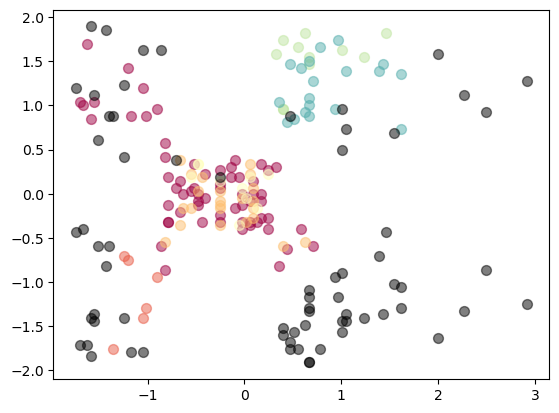

In [44]:
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Black used for noise.
        col = 'black'

    class_member_mask = (labels == k)

    # Plot the datapoints that are clustered
    xy = X[class_member_mask & core_samples_mask]
    plt.scatter(xy[:, 2], xy[:, 3],s=50, c=[col], marker=u'o', alpha=0.5)

    # Plot the outliers
    xy = X[class_member_mask & ~core_samples_mask]
    plt.scatter(xy[:, 2], xy[:, 3],s=50, c=[col], marker=u'o', alpha=0.5)

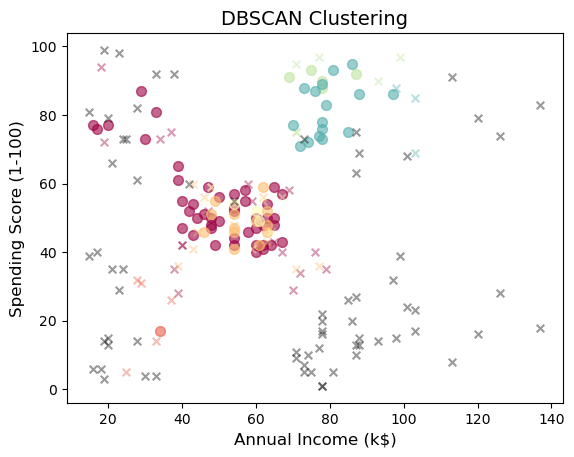

In [45]:
# بازیابی داده اصلی برای رسم (نه استاندارد شده)
original_data = featureset.values  # داده اصلی قبل از استاندارد
income_original = original_data[:, 2]  # Annual Income اصلی
score_original = original_data[:, 3]   # Spending Score اصلی

for k, col in zip(unique_labels, colors):
    if k == -1:
        col = 'black'
    class_member_mask = (labels == k)
    
    # نقاط اصلی خوشه
    xy = original_data[class_member_mask & core_samples_mask]
    plt.scatter(xy[:, 2], xy[:, 3], s=50, c=[col], marker='o', alpha=0.6)
    
    # نقاط outlier
    xy = original_data[class_member_mask & ~core_samples_mask]
    plt.scatter(xy[:, 2], xy[:, 3], s=30, c=[col], marker='x', alpha=0.4)

plt.xlabel('Annual Income (k$)', fontsize=12)
plt.ylabel('Spending Score (1-100)', fontsize=12)
plt.title('DBSCAN Clustering', fontsize=14)
plt.show()